In [98]:
%matplotlib inline
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [99]:
from pathlib import Path

import pandas as pd
from matplotlib import pyplot as plt
from scipy import stats
import numpy as np

from notebooks.imports import *
from src.utils import pmf_utils

### Config

In [100]:
from config import dir_config

raw_dir = Path(dir_config.data.raw)
processed_dir = Path(dir_config.data.processed)

### Utils functions

In [ ]:
def plot_psych(x, y, x_hat, y_hat) -> None:
    fig, ax = plt.subplots()
    ax.plot(x, y, "o", label="Original Data")
    ax.plot(x_hat, y_hat, "r-", label="Fitted Curve")
    ax.set_xlabel("Coherence")
    ax.set_ylabel("Probability of Correct Response")
    ax.set_xlim(-100, 100)
    ax.set_ylim(0, 1)
    ax.legend()
    plt.show()


def plot_pulse_psych(psych_curves, ms=10, lw=3, alpha=1.0, suptitle="", fig=None, ax=None, legend=True):
    """
    Plot psychometric curves for early, mid, and late pulses with control, positive, and negative conditions.
    """

    # Create figure and axes if not provided
    if fig is None or ax is None:
        fig, ax = plt.subplots(1, 3, figsize=(18, 6))

    # Mapping of pulse stage to subplot index
    pulse_map = {1: 0, 2: 1, 3: 2}
    pulse_labels = {1: "Early Pulse", 2: "Mid Pulse", 3: "Late Pulse"}

    def plot_single_pulse(ax, pulse_id, title):
        """Helper to plot a single pulse stage (early, mid, late)."""
        # Plot control
        ax.plot(psych_curves[0]["x"], psych_curves[0]["y"], "ko", ms=ms, alpha=alpha)
        ax.plot(psych_curves[0]["x_hat"], psych_curves[0]["y_hat"], "k-", lw=lw, alpha=alpha, label="Control")
        if psych_curves[0].get("y_err") is not None:
            ax.errorbar(psych_curves[0]["x"], psych_curves[0]["y"], yerr=psych_curves[0]["y_err"], fmt="none", ecolor="k", alpha=alpha)

        # Plot positive pulse
        ax.plot(psych_curves[pulse_id]["x"], psych_curves[pulse_id]["y"], "bo", ms=ms, alpha=alpha)
        ax.plot(psych_curves[pulse_id]["x_hat"], psych_curves[pulse_id]["y_hat"], "b-", lw=lw, alpha=alpha, label=f"{title.split()[0]} Positive")
        if psych_curves[pulse_id].get("y_err") is not None:
            ax.errorbar(psych_curves[pulse_id]["x"], psych_curves[pulse_id]["y"], yerr=psych_curves[pulse_id]["y_err"], fmt="none", ecolor="b", alpha=alpha)

        # Plot negative pulse
        ax.plot(psych_curves[-pulse_id]["x"], psych_curves[-pulse_id]["y"], "ro", ms=ms, alpha=alpha)
        ax.plot(psych_curves[-pulse_id]["x_hat"], psych_curves[-pulse_id]["y_hat"], "r-", lw=lw, alpha=alpha, label=f"{title.split()[0]} Negative")
        if psych_curves[-pulse_id].get("y_err") is not None:
            ax.errorbar(psych_curves[-pulse_id]["x"], psych_curves[-pulse_id]["y"], yerr=psych_curves[-pulse_id]["y_err"], fmt="none", ecolor="r", alpha=alpha)

        # Formatting
        ax.set(xlabel="Coherence", ylabel="Probability of Positive Response", title=title, xlim=(-105, 105), ylim=(-0.05, 1.05))
        ax.set_xticks(psych_curves[0]["x"])
        ax.tick_params(axis="both", labelsize=16)
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)
        ax.grid(False)
        if legend:
            ax.legend()

    # Iterate through pulse stages that exist in psych_curves
    for pulse_id, idx in pulse_map.items():
        if pulse_id in psych_curves:
            plot_single_pulse(ax[idx], pulse_id, pulse_labels[pulse_id])

    if suptitle:
        fig.suptitle(suptitle, fontsize=24)

    fig.tight_layout()
    return fig, ax

In [103]:
subject_sessions = data.groupby("subject_id")["session_id"].nunique().reset_index(name="count")
subject_sessions

,subject_id,count
0,DBM11,15
1,DBM12,17
2,DBM13,5
3,DBM14,16
4,DBM15,33
5,DBM16,9
6,DBM5,23
7,DBM6,27
8,DBM8,13
9,PSUIM10,8


In [104]:
np.sum(subject_sessions["count"].values)

234

### Plot psychometric functions

In [105]:
np.sort(data.pulse_type.unique())

array([-3, -2, -1,  0,  1,  2,  3])

In [106]:
# run utils.get_psychometric_curve function for each subset of pulse_type
psych_curves = {}

for pulse_type in data.pulse_type.unique():
    x, y, model, x_hat, y_hat = pmf_utils.get_psychometric_data(data[data.pulse_type == pulse_type], model_type="logit_3", x_model_range=[-100, 100])

    psych_curves[pulse_type] = {
        "x": x,
        "y": y,
        "model": model,
        "x_hat": x_hat,
        "y_hat": y_hat,
    }

(<Figure size 1800x600 with 3 Axes>,
 array([<Axes: title={'center': 'Early Pulse'}, xlabel='Coherence', ylabel='Probability of Positive Response'>,
        <Axes: title={'center': 'Mid Pulse'}, xlabel='Coherence', ylabel='Probability of Positive Response'>,
        <Axes: title={'center': 'Late Pulse'}, xlabel='Coherence', ylabel='Probability of Positive Response'>],
       dtype=object))

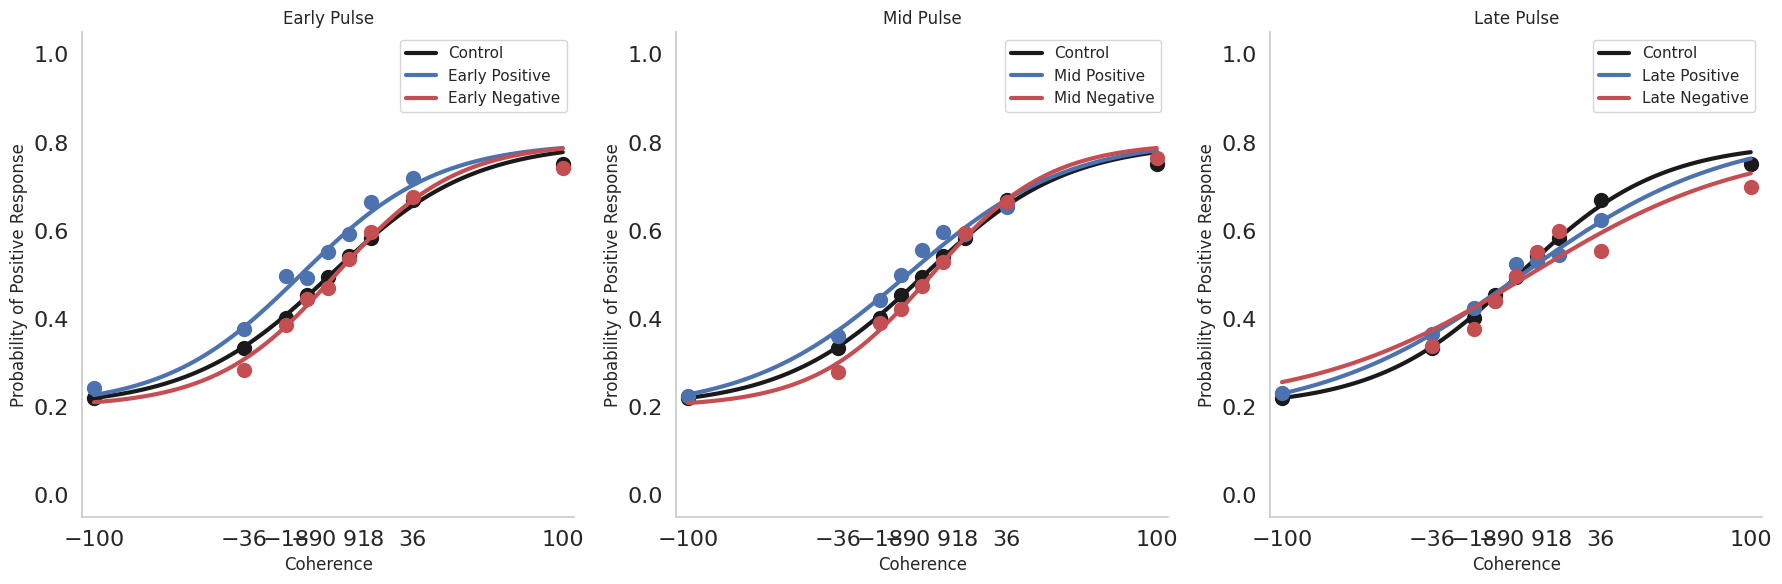

In [107]:
plot_pulse_psych(psych_curves)

In [108]:
# run utils.get_psychometric_curve function for each subset of pulse_type
pmf_data_by_subject = {}
for subject_id in data.subject_id.unique():
    subject_data = data[data.subject_id == subject_id]

    psych_curves = {}

    for pulse_type in subject_data.pulse_type.unique():
        x, y, model, x_hat, y_hat = pmf_utils.get_psychometric_data(subject_data[subject_data.pulse_type == pulse_type], model_type="logit_3", x_model_range=[-100, 100])

        psych_curves[pulse_type] = {
            "x": x,
            "y": y,
            "model": model,
            "x_hat": x_hat,
            "y_hat": y_hat,
        }
    pmf_data_by_subject[subject_id] = psych_curves

In [109]:
subject_id

'PSUIM9'

In [110]:
pmf_data_by_subject[subject_id][pulse_type]["y"]

array([0.40625   , 0.63636364, 0.63157895, 0.64516129, 0.78947368,
       0.78947368, 0.94285714, 1.        ])

(<Figure size 1800x600 with 3 Axes>,
 array([<Axes: title={'center': 'Early Pulse'}, xlabel='Coherence', ylabel='Probability of Positive Response'>,
        <Axes: title={'center': 'Mid Pulse'}, xlabel='Coherence', ylabel='Probability of Positive Response'>,
        <Axes: title={'center': 'Late Pulse'}, xlabel='Coherence', ylabel='Probability of Positive Response'>],
       dtype=object))

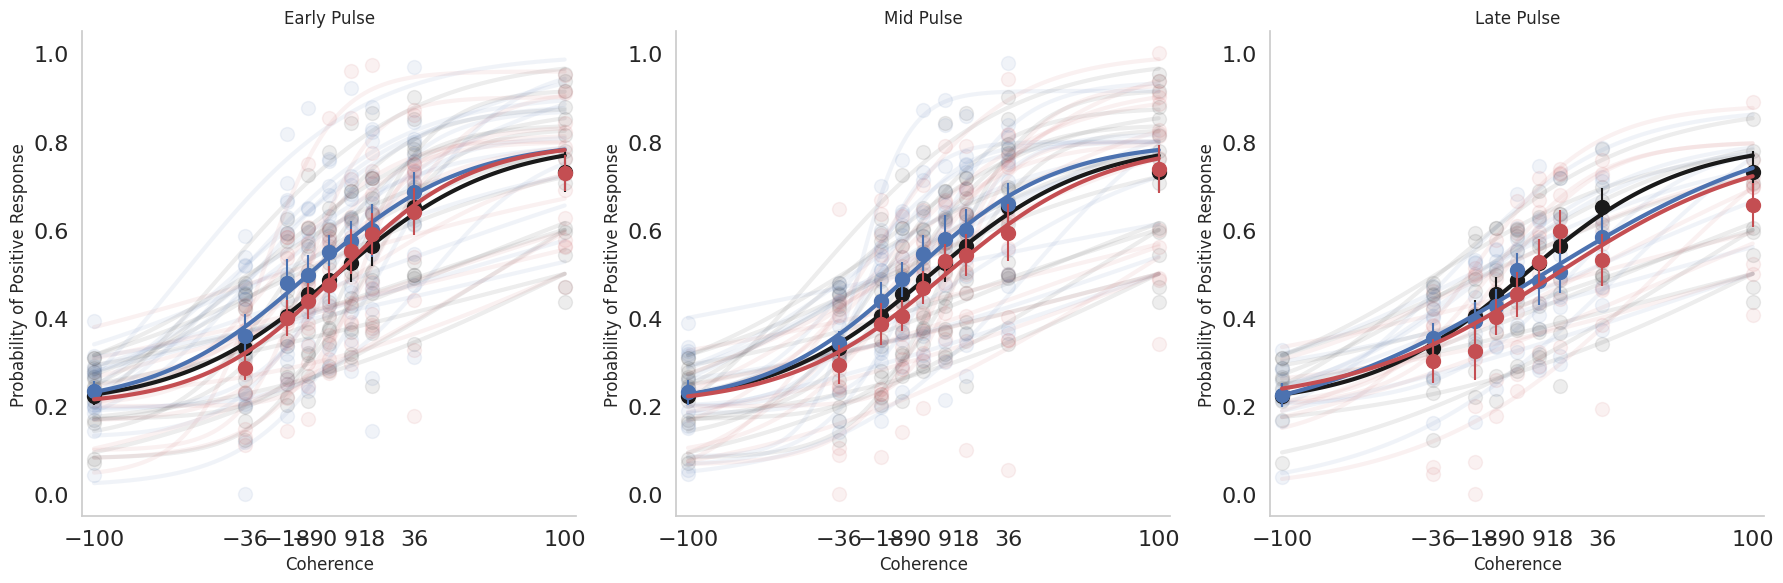

In [113]:
fig, axs = plt.subplots(1, 3, figsize=(18, 6))

x_data, y_data, x_hat, y_hat = {}, {}, {}, {}

for subject_id in data.subject_id.unique():
    plot_pulse_psych(pmf_data_by_subject[subject_id], legend=False, alpha=0.08, fig=fig, ax=axs)

    for pulse_type in pmf_data_by_subject[subject_id]:
        if pulse_type not in x_data:
            x_data[pulse_type] = [pmf_data_by_subject[subject_id][pulse_type]["x"]]
            y_data[pulse_type] = [pmf_data_by_subject[subject_id][pulse_type]["y"]]
            x_hat[pulse_type] = [pmf_data_by_subject[subject_id][pulse_type]["x_hat"]]
            y_hat[pulse_type] = [pmf_data_by_subject[subject_id][pulse_type]["y_hat"]]
        else:
            y_data[pulse_type].append(pmf_data_by_subject[subject_id][pulse_type]["y"])
            y_hat[pulse_type].append(pmf_data_by_subject[subject_id][pulse_type]["y_hat"])

avg_psych_curves = {}
for pulse_type in sorted(x_data.keys()):
    x = np.nanmean(x_data[pulse_type], axis=0)
    y = np.nanmean(y_data[pulse_type], axis=0)

    model = pmf_utils.fit_psychometric_function(x, y, trial_counts=None, model_type="logit_3")
    # Generate model predictions over a range of x values
    x_model_avg = np.linspace(-100, 100, 100)
    y_model_avg = model.predict(x_model_avg)

    avg_psych_curves[pulse_type] = {
        "x": x,
        "y": y,
        "y_err": stats.sem(y_data[pulse_type], axis=0, nan_policy="omit"),
        "model": model,
        "x_hat": x_model_avg,
        "y_hat": y_model_avg,
    }

plot_pulse_psych(avg_psych_curves, legend=False, alpha=1, fig=fig, ax=axs)

# Calculating choice bias based on GLM including pulse information

Kiani et al 2008
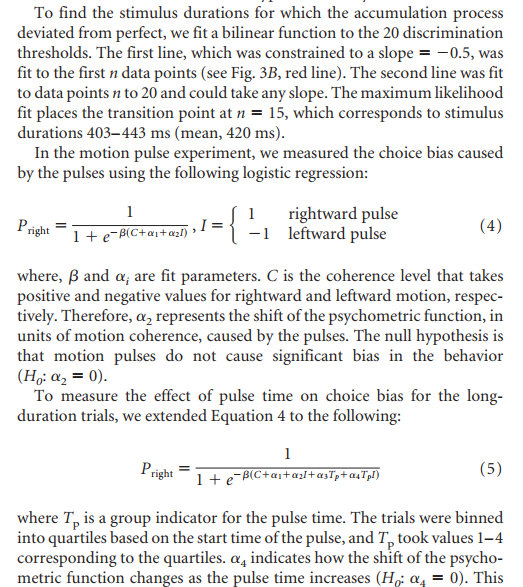

In [114]:
import numpy as np
from scipy.optimize import curve_fit


# Define the model functions
def pulse_glm_fit(x, beta, lapse, alpha_1, alpha_2):
    coh, pulse_dir = x  # Unpack tuple input
    expon_eq = -beta * (coh + alpha_1) + (pulse_dir * alpha_2)
    return lapse + ((1 - 2 * lapse) / (1 + np.exp(expon_eq)))


def pulse_time_glm_fit(x, beta, lapse, alpha_1, alpha_2, alpha_3, alpha_4):
    coh, pulse_dir, pulse_time = x  # Unpack tuple input
    expon_eq = -beta * (coh + alpha_1 + (pulse_dir * alpha_2) + (alpha_3 * pulse_time) + (alpha_4 * (pulse_dir * pulse_time)))
    return lapse + (1 - 2 * lapse) / (1 + np.exp(expon_eq))


def fit(model, x, y):
    # Parameter bounds
    beta = (1e-5, 30)
    lapse = (0, 0.3)
    alpha_1 = (-1, 1)
    alpha_2 = (-1, 1)
    alpha_3 = (-1, 1)
    alpha_4 = (-1, 1)

    param_lims = [beta, lapse, alpha_1]
    if model == "pulse":
        _fit_func = pulse_glm_fit
        param_lims.append(alpha_2)
    elif model == "pulse_time":
        _fit_func = pulse_time_glm_fit
        param_lims.extend([alpha_2, alpha_3, alpha_4])

    # Prepare bounds and initial guess
    bounds = list(zip(*param_lims))
    initial_guess = [np.mean(b) for b in param_lims]  # Use the mean of bounds as initial guess

    sigma = None

    # Fit using curve_fit
    popt, pcov = curve_fit(_fit_func, x, y, p0=initial_guess, bounds=bounds, sigma=sigma, absolute_sigma=False)

    # Print results
    print("Optimized Parameters:", popt)

    return popt, pcov


def get_alpha(pulse_type, model, fit_params):
    pulse_dir = np.sign(pulse_type)
    pulse_time = np.abs(pulse_type)
    if model == "pulse":
        alpha = pulse_dir * fit_params[3]
    elif model == "pulse_time":
        alpha = (pulse_dir * fit_params[3]) + (fit_params[4] * pulse_time) + (fit_params[5] * (pulse_dir * pulse_time))
    return alpha

#### Pulse types
- -3: 'late_negative_pulse'
- -2: 'middle_negative_pulse'
- -1: 'early_negative_pulse'
- 0: 'control'
- 1: 'early_positive_pulse'
- 2: 'middle_positive_pulse'
- 3: 'late_positive_pulse'

In [115]:
# Preprocess DataFrame
pulse_dir = data.pulse_type.map({1: 1, 2: 1, 3: 1, 0: 0, -1: -1, -2: -1, -3: -1}).to_numpy()
pulse_time = np.abs(data.pulse_type.to_numpy())
coh = data.signed_coherence.to_numpy() / 100
y = data.choice.to_numpy().astype(float)  # Ensure `choice` is numerical

# Select model and format `x` correctly
model = "pulse_time"

if model == "pulse":
    x = (coh, pulse_dir)
elif model == "pulse_time":
    x = (coh, pulse_dir, pulse_time)

# Fit model
fit_params, fit_cov = fit(model, x, y)
if model == "pulse":
    y_hat = pulse_glm_fit(x, *fit_params)
elif model == "pulse_time":
    y_hat = pulse_time_glm_fit(x, *fit_params)


alpha_1 = fit_params[2]
alpha_2 = fit_params[3]
alpha_3 = fit_params[4]
alpha_4 = fit_params[5]

Optimized Parameters: [ 3.69036365e+00  2.22993651e-01  3.27347944e-03  1.19604958e-01
 -4.12463956e-04 -3.77997011e-02]


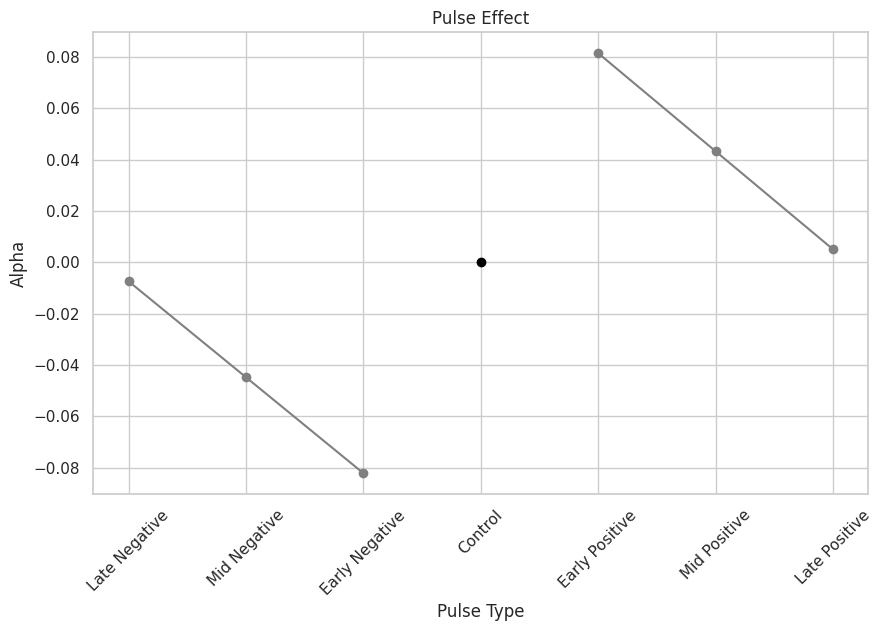

In [116]:
plt.figure(figsize=(10, 6))
pulses = [-3, -2, -1]
plt.plot(pulses, [get_alpha(p, model, fit_params) for p in pulses], "o-", color="gray")
pulses = [1, 2, 3]
plt.plot(pulses, [get_alpha(p, model, fit_params) for p in pulses], "o-", color="gray")
pulses = [0]
plt.plot(pulses, [get_alpha(p, model, fit_params) for p in pulses], "o-", color="black")

plt.xticks([-3, -2, -1, 0, 1, 2, 3], ["Late Negative", "Mid Negative", "Early Negative", "Control", "Early Positive", "Mid Positive", "Late Positive"], rotation=45)
plt.title("Pulse Effect")
plt.xlabel("Pulse Type")
plt.ylabel("Alpha");

# Fit Individual Sesssions and compare relative alpha change ()


📌 GLM Results for Pulse Model:

                 Generalized Linear Model Regression Results                  
Dep. Variable:                 choice   No. Observations:               113874
Model:                            GLM   Df Residuals:                   113871
Model Family:                Binomial   Df Model:                            2
Link Function:                  logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -73539.
Date:                Sun, 09 Nov 2025   Deviance:                   1.4708e+05
Time:                        03:01:41   Pearson chi2:                 1.14e+05
No. Iterations:                     5   Pseudo R-squ. (CS):            0.09035
Covariance Type:            nonrobust                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -0.01

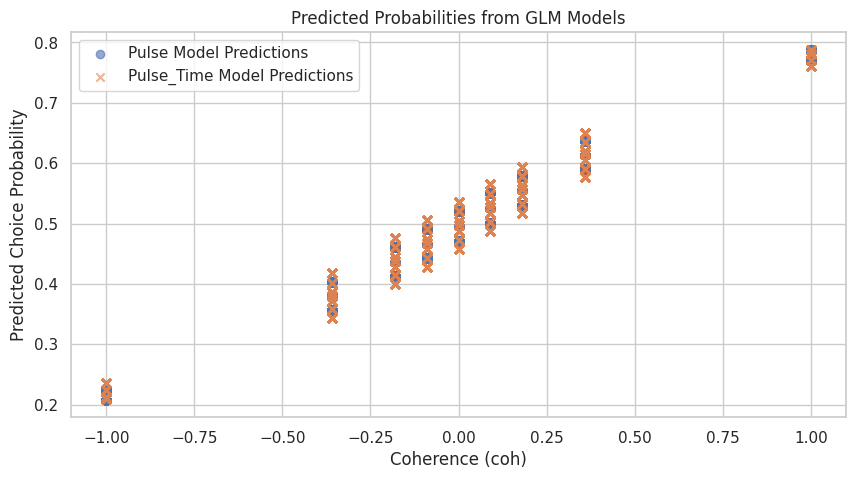

In [117]:
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from statsmodels.genmod.families import Binomial
from statsmodels.genmod.families.links import logit
import matplotlib.pyplot as plt

# Set random seed for reproducibility
np.random.seed(42)

# Generate synthetic data similar to motion energy experiments
glm_data = pd.DataFrame(
    {
        "coh": data.signed_coherence / 100,  # Signed coherence (motion strength)
        "pulse_dir": data.pulse_type.map({1: 1, 2: 1, 3: 1, 0: 0, -1: -1, -2: -1, -3: -1}),  # Direction of the pulse
        "pulse_time": np.abs(data.pulse_type),  # Time of the pulse event
        "choice": data.choice.astype(float),  # Binary response (0 or 1)
    }
)

### **1️⃣ Fit GLM for Pulse Model (without pulse_time)**
formula_pulse = "choice ~ coh + pulse_dir"
glm_pulse = smf.glm(formula=formula_pulse, data=glm_data, family=Binomial(link=logit())).fit()

print("\n📌 GLM Results for Pulse Model:\n")
print(glm_pulse.summary())

### **2️⃣ Fit GLM for Pulse_Time Model (including pulse_time interaction)**
formula_pulse_time = "choice ~ coh + pulse_dir + pulse_time + pulse_dir:pulse_time"
glm_pulse_time = smf.glm(formula=formula_pulse_time, data=glm_data, family=Binomial(link=logit())).fit()

print("\n📌 GLM Results for Pulse_Time Model:\n")
print(glm_pulse_time.summary())

### **3️⃣ Model Comparison using AIC (lower is better)**
print("\n✅ Model Comparison (Lower AIC is better):")
print(f"AIC for Pulse Model: {glm_pulse.aic}")
print(f"AIC for Pulse_Time Model: {glm_pulse_time.aic}")

### **4️⃣ Predict probabilities using the fitted model**
glm_data["predicted_choice_pulse"] = glm_pulse.predict(glm_data)
glm_data["predicted_choice_pulse_time"] = glm_pulse_time.predict(glm_data)


### **5️⃣ Plot Model Predictions**

plt.figure(figsize=(10, 5))
plt.scatter(glm_data["coh"], glm_data["predicted_choice_pulse"], label="Pulse Model Predictions", alpha=0.6)
plt.scatter(glm_data["coh"], glm_data["predicted_choice_pulse_time"], label="Pulse_Time Model Predictions", alpha=0.6, marker="x")
plt.xlabel("Coherence (coh)")
plt.ylabel("Predicted Choice Probability")
plt.legend()
plt.title("Predicted Probabilities from GLM Models")
plt.show()

# TEST